# Bank marketing: transformations and collinearity

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox, norm, gaussian_kde
from sklearn.decomposition import PCA, SparsePCA
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

Data from Moro, S., Cortez, P. & Rita, P. (2014) A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22-31 (UCI Machine Learning Repository, file `bank-additional.csv`).

Each row is a phone call of a marketing campaign of a Portuguese bank. We use the duration of the call (in seconds) and five social and economic indicators of the moment of the call.

In [2]:
dat = pd.read_csv('bank_additional.csv', sep=';')
dat = dat[['duration', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']]

In [3]:
# Brief description of the data
dat.describe()

,duration,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000,4119.000000
mean,256.788055,0.084972,93.579704,-40.499102,3.621356,5166.481695
std,254.703736,1.563114,0.579349,4.594578,1.733591,73.667904
min,0.000000,-3.400000,92.201000,-50.800000,0.635000,4963.600000
25%,103.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000
50%,181.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,317.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,3643.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [4]:
def plot_heatmap(ax, values, row_labels, col_labels, cmap, vmin, vmax, white_above=0.6):
    # Annotated heatmap with a white gap between the cells
    im = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax)
    n_rows, n_cols = values.shape
    for i in range(n_rows):
        for j in range(n_cols):
            dark = abs(values[i, j]) > white_above*max(abs(vmin), abs(vmax))
            ax.text(j, i, f'{round(values[i, j], 2) + 0:.2f}', ha='center', va='center', fontsize=11,
                    color='white' if dark else '#333333')
    ax.set_xticks(range(n_cols), col_labels, rotation=30, ha='right')
    ax.set_yticks(range(n_rows), row_labels)
    ax.set_xticks(np.arange(n_cols+1)-0.5, minor=True)
    ax.set_yticks(np.arange(n_rows+1)-0.5, minor=True)
    ax.grid(which='minor', color='white', linewidth=3)
    ax.tick_params(which='both', length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return im

def variance_decomposition(X):
    # Condition indexes and variance-decomposition proportions of a matrix
    u, d, vt = np.linalg.svd(X, full_matrices=False)
    phis = vt.T**2/d**2
    return d[0]/d, phis.T/sum(phis.T)

## Duration of the calls: Box-Cox transformation

The duration is very asymmetric.

In [5]:
def hist_variable(ax, values, xlabel, title):
    grid = np.linspace(values.min(), values.max(), 400)
    ax.hist(values, bins=60, density=True, color='#cfe8f3', edgecolor='white', linewidth=0.5, label='Histogram')
    ax.plot(grid, gaussian_kde(values)(grid), color='#1f4e79', lw=2, label='Kernel estimator')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Density')
    ax.set_title(title)
    ax.grid(True, alpha=0.25)
    return grid

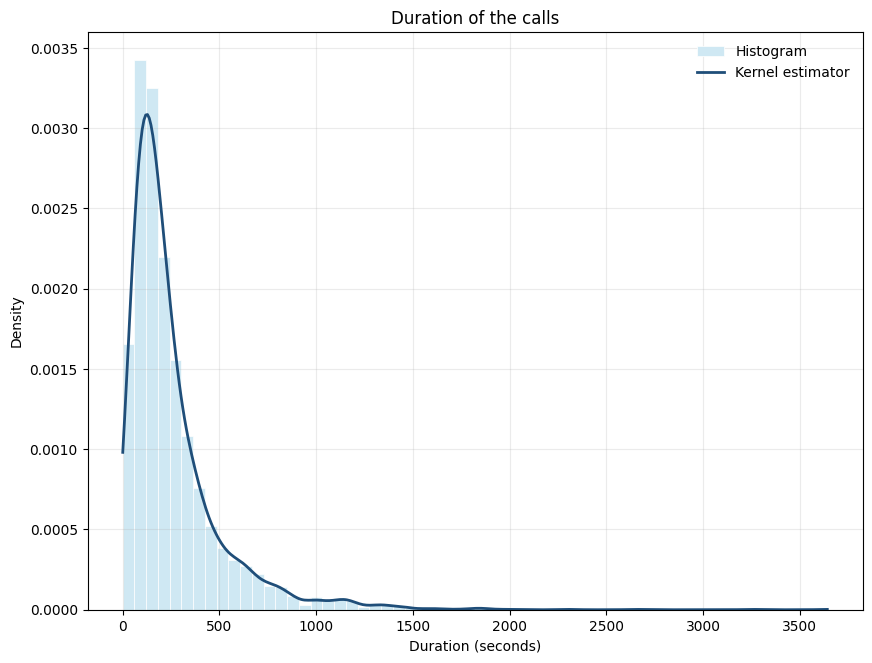

In [6]:
fig, ax = plt.subplots(figsize=(10, 7.5))
hist_variable(ax, dat['duration'].to_numpy(), 'Duration (seconds)', 'Duration of the calls')
ax.legend(loc='upper right', frameon=False);

The Box-Cox transformation
$$y^{(\lambda)} = \frac{y^\lambda-1}{\lambda}$$
needs positive values, so we drop the calls with duration zero. `boxcox` chooses $\lambda$ by maximum likelihood.

In [7]:
dat = dat[dat['duration'] > 0].reset_index(drop=True)
n = len(dat)

duration_transform, lamb = boxcox(dat['duration'])

print('lambda:', lamb)
print('Mean:  ', np.mean(duration_transform))
print('Std:   ', np.std(duration_transform))

lambda: 0.14373775105519732
Mean:   7.786876012239264
Std:    1.9060621854141944


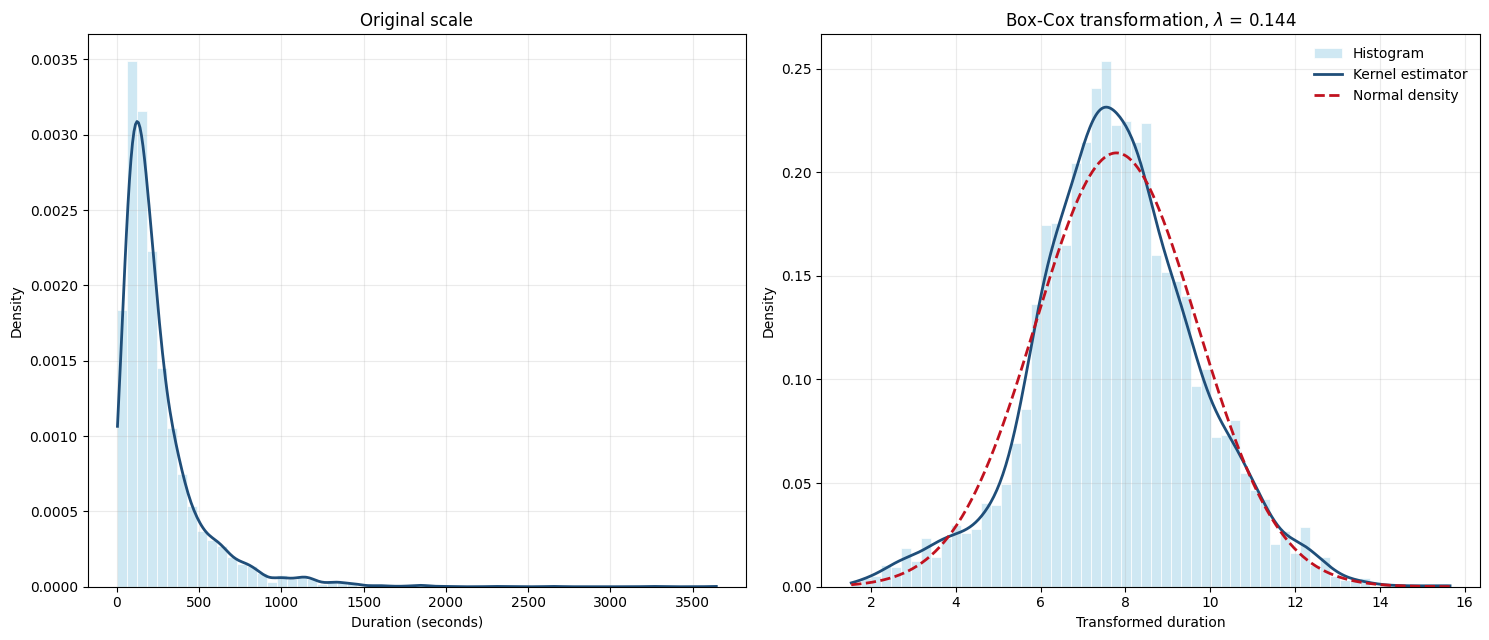

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
hist_variable(axes[0], dat['duration'].to_numpy(), 'Duration (seconds)', 'Original scale')
grid = hist_variable(axes[1], duration_transform, 'Transformed duration', f'Box-Cox transformation, $\\lambda$ = {lamb:.3f}')
axes[1].plot(grid, norm.pdf(grid, np.mean(duration_transform), np.std(duration_transform)), '--', color='#c1121f',
             lw=2, label='Normal density')
axes[1].legend(loc='upper right', frameon=False)
plt.tight_layout()

The transformation can be inverted to go back to seconds.

In [9]:
(duration_transform*lamb+1)**(1/lamb)

array([487., 346., 227., ...,  64., 528., 175.], shape=(4118,))

In [10]:
dat['duration_transform'] = duration_transform

## Social and economic data: collinearity

In [11]:
features = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
dat_social_economic = dat[features]
np.round(dat_social_economic.describe(), 3)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,4118.000,4118.000,4118.000,4118.000,4118.000
mean,0.085,93.580,-40.500,3.621,5166.476
std,1.563,0.579,4.595,1.734,73.676
min,-3.400,92.201,-50.800,0.635,4963.600
25%,-1.800,93.075,-42.700,1.334,5099.100
50%,1.100,93.749,-41.800,4.857,5191.000
75%,1.400,93.994,-36.400,4.961,5228.100
max,1.400,94.767,-26.900,5.045,5228.100


The condition number is too big: `nr.employed` has a different scale than the other features. It is better to standardize the data.

In [12]:
print(f'Condition number: {np.linalg.cond(dat_social_economic):.2f}')

Condition number: 26088.67


In [13]:
dat_social_economic_scale = StandardScaler().fit_transform(dat_social_economic)
dat_social_economic_scale = pd.DataFrame(dat_social_economic_scale, columns=features)

print(f'Condition number: {np.linalg.cond(dat_social_economic_scale):.2f}')

Condition number: 17.69


The condition number is lower now, but it still points to moderate or high correlation between the variables. Belsley, Kuh and Welsch extend a suggestion of Kendall and Silvey: there are as many near dependencies among the columns of a data matrix as there are high condition indexes. Weak dependencies are associated with condition indexes around 5 or 10, moderate to strong relations with condition indexes of 30 to 100.

### Correlations

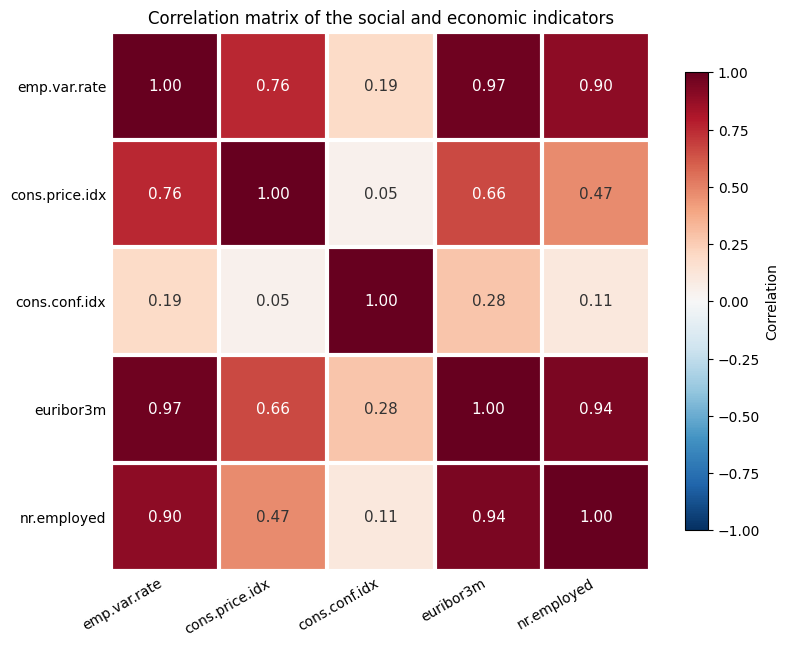

In [14]:
corr_matrix = dat_social_economic_scale.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = plot_heatmap(ax, corr_matrix.to_numpy(), features, features, 'RdBu_r', -1, 1)
fig.colorbar(im, ax=ax, label='Correlation', shrink=0.85)
ax.set_title('Correlation matrix of the social and economic indicators');

Four variables, all except `cons.conf.idx`, are highly correlated. Especially `euribor3m` with `emp.var.rate` and `nr.employed`: we could just keep one of them.

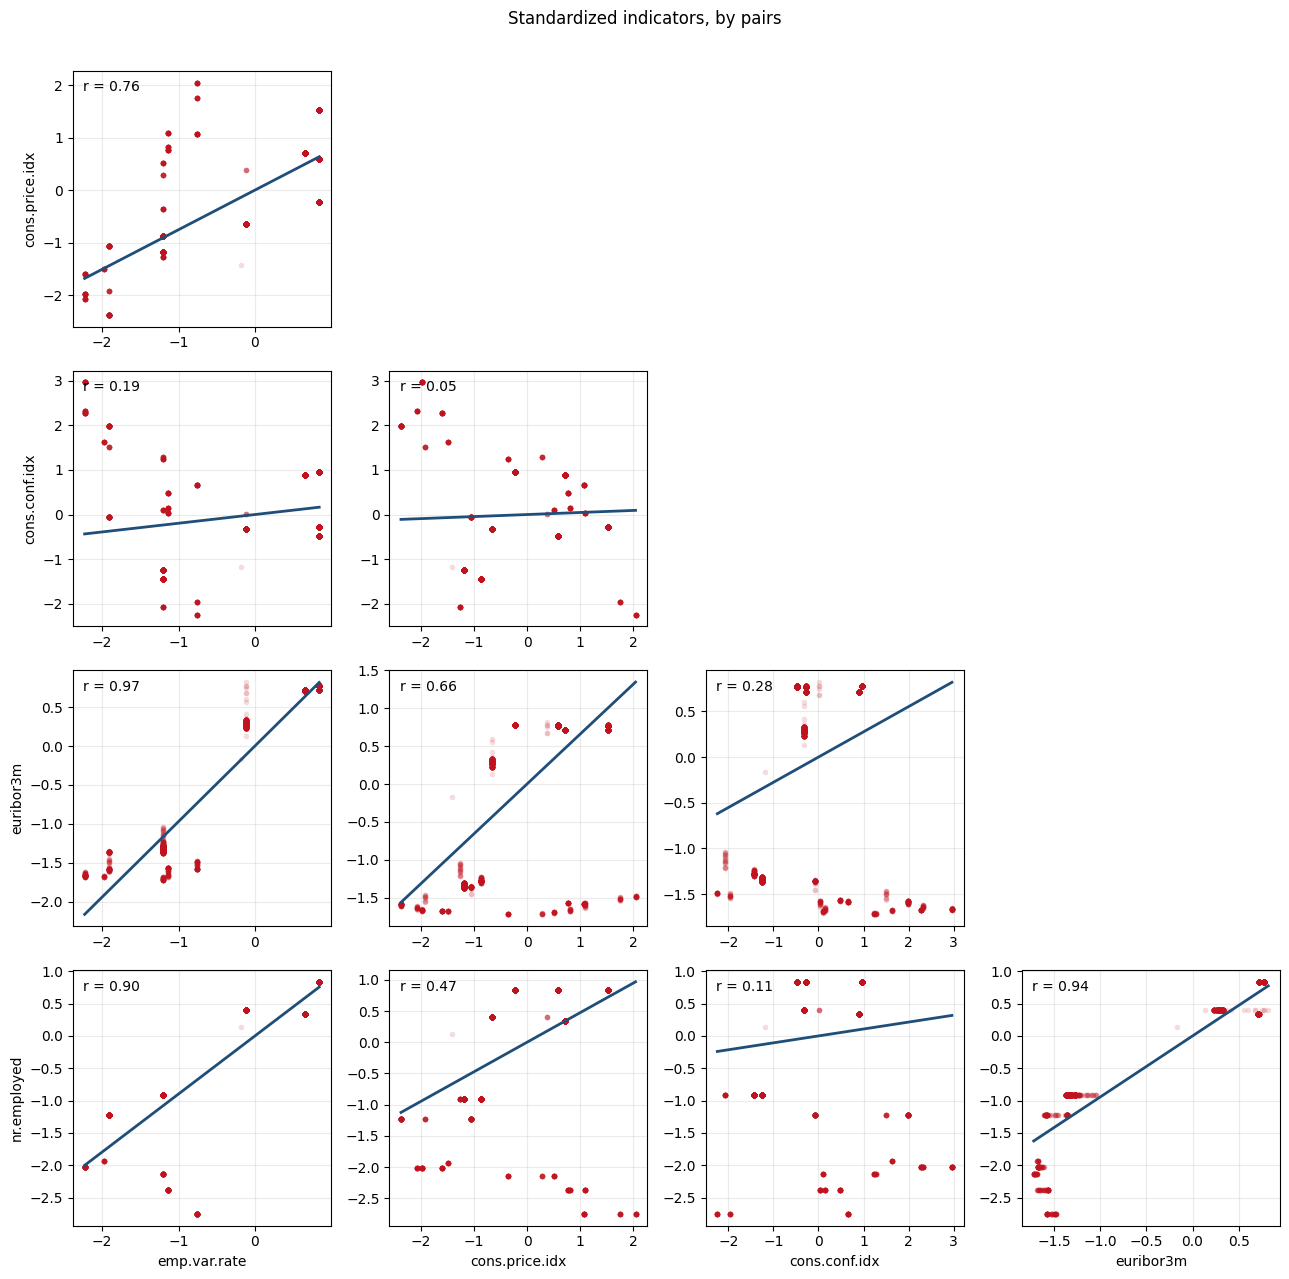

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for i in range(1, 5):
    for j in range(4):
        ax = axes[i-1, j]
        if j >= i:
            ax.set_axis_off()
            continue
        x_j = dat_social_economic_scale[features[j]].to_numpy()
        x_i = dat_social_economic_scale[features[i]].to_numpy()
        line = np.polyfit(x_j, x_i, 1)
        x_line = np.array([x_j.min(), x_j.max()])
        ax.plot(x_j, x_i, 'o', color='#c1121f', markersize=4, alpha=0.15, markeredgewidth=0)
        ax.plot(x_line, np.polyval(line, x_line), color='#1f4e79', lw=2)
        ax.annotate(f'r = {corr_matrix.iloc[i, j]:.2f}', (0.04, 0.92), xycoords='axes fraction', fontsize=10)
        ax.grid(True, alpha=0.25)
        if j == 0:
            ax.set_ylabel(features[i])
        if i == 4:
            ax.set_xlabel(features[j])
fig.suptitle('Standardized indicators, by pairs')
fig.tight_layout(rect=(0, 0, 1, 0.97))

### Variance inflation factors

One recommendation is that if the VIF is greater than 5, the variable is highly collinear with the others, and its coefficient will have a large standard error. The VIFs are also the diagonal of the inverse of the correlation matrix.

In [16]:
vif = pd.DataFrame({
    'feature': features,
    'VIF': [variance_inflation_factor(dat_social_economic_scale.values, j) for j in range(len(features))],
    'n diag((X^T X)^-1)': np.diag(np.linalg.inv(dat_social_economic_scale.T @ dat_social_economic_scale))*n,
    'diag(R^-1)': np.diag(np.linalg.inv(corr_matrix))})
vif.round(2)

,feature,VIF,n diag((X^T X)^-1),diag(R^-1)
0,emp.var.rate,31.68,31.68,31.68
1,cons.price.idx,6.29,6.29,6.29
2,cons.conf.idx,2.49,2.49,2.49
3,euribor3m,62.36,62.36,62.36
4,nr.employed,30.13,30.13,30.13


### Condition indexes and variance decomposition

In [17]:
cond_index, var_decomp_proportions = variance_decomposition(dat_social_economic_scale)
np.round(cond_index, 2)

array([ 1.  ,  1.86,  2.48, 11.45, 17.69])

There are two condition indexes above 10, the rest are below 5: there are two collinearities in the data.

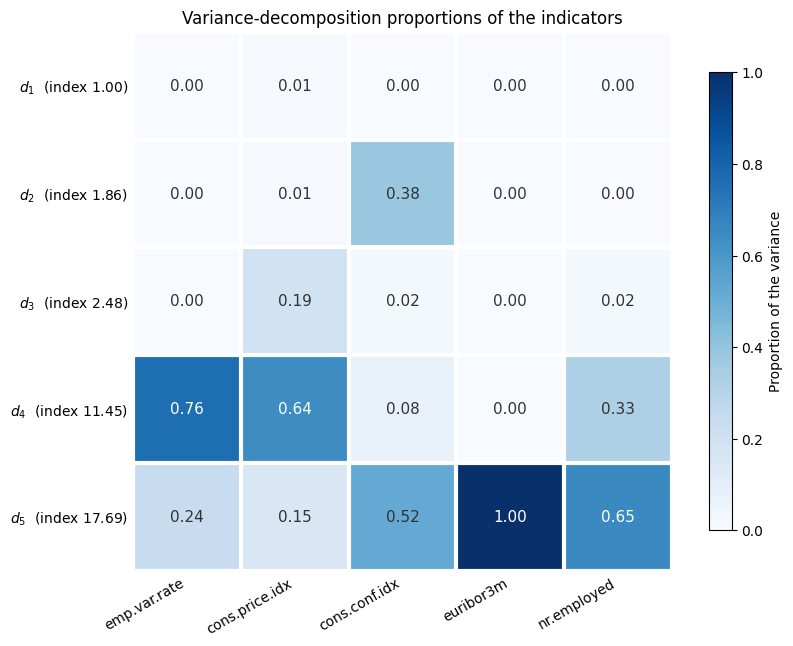

In [18]:
fig, ax = plt.subplots(figsize=(9.5, 7))
row_labels = [f'$d_{k+1}$  (index {cond_index[k]:.2f})' for k in range(len(cond_index))]
im = plot_heatmap(ax, var_decomp_proportions, row_labels, features, 'Blues', 0, 1)
fig.colorbar(im, ax=ax, label='Proportion of the variance', shrink=0.85)
ax.set_title('Variance-decomposition proportions of the indicators');

This suggests a collinearity between the last three variables (especially `euribor3m` and `nr.employed`), associated with the largest condition index, and another collinearity between the first two, `emp.var.rate` and `cons.price.idx`.

## A solution: principal components

The principal components are uncorrelated linear combinations of the variables, so they do not have collinearity.

In [19]:
PCA_data = PCA()
PCA_data.fit(dat_social_economic_scale)
PCA_loads = PCA_data.components_
Z = PCA_data.transform(dat_social_economic_scale)
var_per_pca_component = np.diag(Z.T @ Z)/sum(np.diag(Z.T @ Z))

np.round(pd.DataFrame(Z).corr(), 3) + 0

,0,1,2,3,4
0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0


But each component is a combination of all the variables, which makes them hard to interpret. Sparse principal components force many loadings to be exactly zero. The price is that the components are no longer uncorrelated; to measure the variance they explain we use the QR decomposition of the transformed data.

In [20]:
SPCA = SparsePCA(n_components=5, alpha=10, random_state=111)
SPCA.fit(dat_social_economic_scale)
SPCA_loads = -1*SPCA.components_

q, r = np.linalg.qr(SPCA.transform(dat_social_economic_scale))
diag_r = np.diag(r**2)
var_per_sparse_component = diag_r/sum(diag_r)

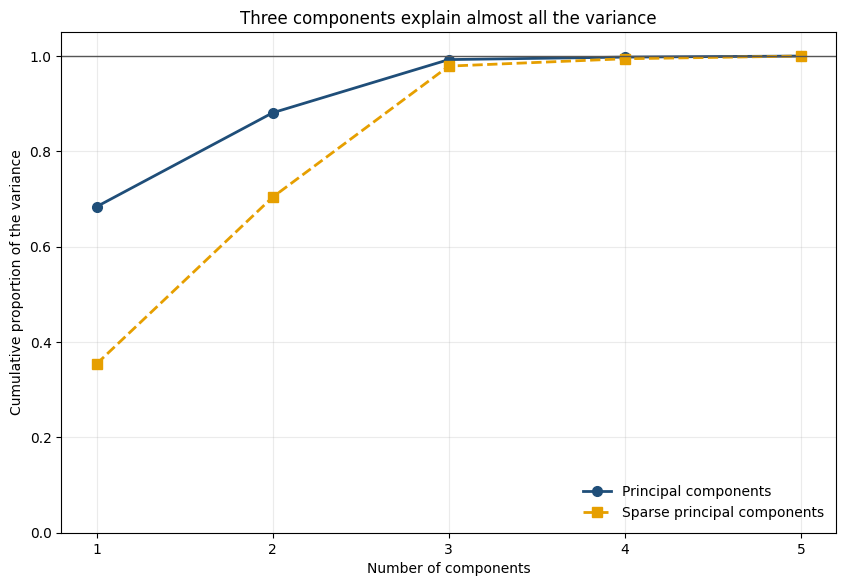

In [21]:
fig, ax = plt.subplots(figsize=(10, 6.5))
components = np.arange(1, 6)
ax.plot(components, np.cumsum(var_per_pca_component), 'o-', color='#1f4e79', lw=2, markersize=7, label='Principal components')
ax.plot(components, np.cumsum(var_per_sparse_component), 's--', color='#E69F00', lw=2, markersize=7,
        label='Sparse principal components')
ax.axhline(1, color='#555555', lw=1)
ax.set_xticks(components)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative proportion of the variance')
ax.set_title('Three components explain almost all the variance')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, alpha=0.25)

Three components is the right number.

In [22]:
SPCA = SparsePCA(n_components=3, alpha=10, random_state=111)
SPCA.fit(dat_social_economic_scale)
SPCA_loads = -1*SPCA.components_
spca_names = ['SparsePC1', 'SparsePC2', 'SparsePC3']

transform_data_SPCA = pd.DataFrame(SPCA.transform(dat_social_economic_scale), columns=spca_names)

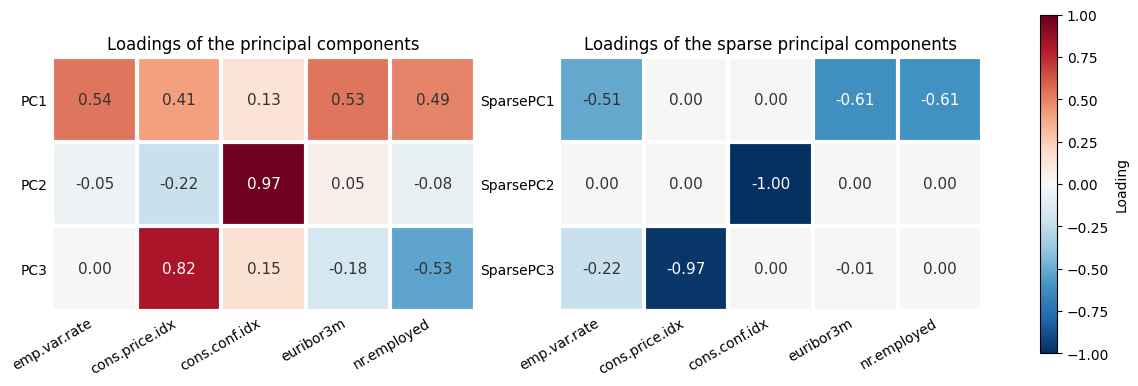

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
limit = np.abs(np.r_[PCA_loads[:3].ravel(), SPCA_loads.ravel()]).max()
plot_heatmap(axes[0], PCA_loads[:3], ['PC1', 'PC2', 'PC3'], features, 'RdBu_r', -limit, limit)
axes[0].set_title('Loadings of the principal components')
im = plot_heatmap(axes[1], SPCA_loads, spca_names, features, 'RdBu_r', -limit, limit)
axes[1].set_title('Loadings of the sparse principal components')
fig.colorbar(im, ax=axes, label='Loading', shrink=0.8)

The sparse components are correlated, but much less than the original variables.

In [24]:
np.round(transform_data_SPCA.corr(), 3)

,SparsePC1,SparsePC2,SparsePC3
SparsePC1,1.000,0.202,0.584
SparsePC2,0.202,1.000,0.050
SparsePC3,0.584,0.050,1.000


In [25]:
print(f'Condition number: {np.linalg.cond(transform_data_SPCA):.2f}')

Condition number: 2.33


In [26]:
cond_index_spca, var_decomp_proportions_spca = variance_decomposition(transform_data_SPCA)
np.round(cond_index_spca, 2)

array([1.  , 1.79, 2.33])

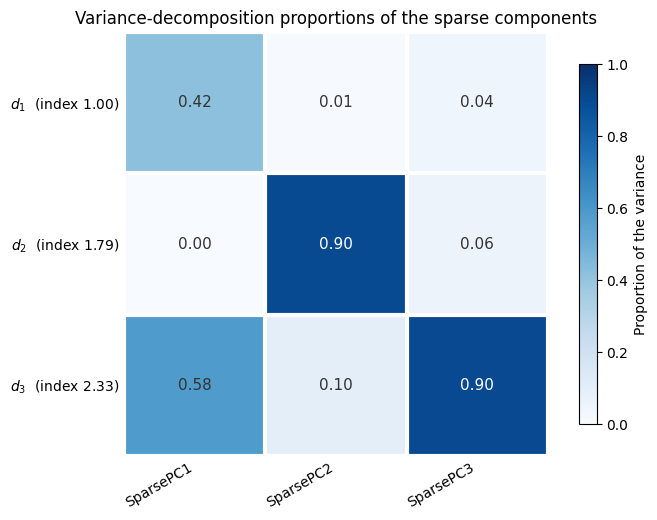

In [27]:
fig, ax = plt.subplots(figsize=(8, 5.5))
row_labels = [f'$d_{k+1}$  (index {cond_index_spca[k]:.2f})' for k in range(3)]
im = plot_heatmap(ax, var_decomp_proportions_spca, row_labels, spca_names, 'Blues', 0, 1)
fig.colorbar(im, ax=ax, label='Proportion of the variance', shrink=0.85)
ax.set_title('Variance-decomposition proportions of the sparse components');

All the condition indexes are now small: the three sparse components keep the information of the five indicators without the collinearity.